# 📘 10.1 Direct and Relaxation Finite-Difference Methods
###

This notebook introduces **finite-difference** methods for solving **boundary value problems**, starting with a quick refresh on forming finite-difference representations of gradients, before explaining how these can be inserted into an ODE to create a discretised solution domain. This approach allows the formation of a linear system that can be solved using methods introduced in Week 2, or via iterative relaxation methods, with examples provided for each approach.


---

### 🎯 Learning Objectives
> By the end of this notebook, you should be able to:
>
> * formulate finite difference stensils for derivatives by combining Taylor series expansions;
> * divide a solution domain into a series of points (nodes) at which the ODE can be locally expressed via finite difference stencils;
> * form a linear system whose solutions must satisfy the ODE and boundary condition of the *boundary value problem*;
> * recognise how sparse linear systems solution methods can be used to efficiently solve the sparse systems typical of ODEs;
> * explain the limits of shooting methods approach, and the situations in which a finite difference method is more appropriate;
> * formulate Jacobi and Gauss-Seidel relaxation methods expressions for iterative finite difference solutions;
> * understand why relaxation methods can diverge for some ODEs with small step sizes.

## 📂 10.1.0 How to use this notebook

This notebook introduces the **finite difference** formulation for solving boundary value problems, and demonstrate how this can be used to formulate a linear system that can either be solved directly using previous introduced methods (week 2), or by relaxation methods.

> ### 🧭 Theory preface
> The processes followed here are general and can be applied to different ODEs. However, unlike many of the linear system and interpolation routines, the equations formed here are specific to a given ODE, the order of the finite difference approximation, and the boundary conditions. It is therefore essential that you are able to follow the methods introduced here to effectively formulate the system that can be computationally solved.
>
> The setup is the important and difficult part. The code required to solve this is relatively simple, and can be easily generated by AI, once you have done the work of setting up the problem.


## 📂 10.1.1 Finite Difference Approximation to Derivatives

---

In [Notebook 7.1](https://colab.research.google.com/drive/1BXXPZqPI16IT7ihibSp5_jhU4i3TaeeW?usp=playground) we showed how Taylor's Series can be used to formulate multipoint, discretised *stencils* that represent local gradients based on values in adjacent points.

Let's take a moment to go back over general process.

> A Taylor Series representation of the function $f(x+h)$ about a point $x$ is given by:
$$f(x+h)= f(x)+ f'(x)h+ \frac{f''(x)}{2!}h^2+ \frac{f^{(3)}(x)}{3!}h^3+ \mathcal{O}(h^4)\tag{10.1}$$
>
> From equation 10.1 we can rearrange this in to an expression for $f'(x)$,
$$f'(x)=\frac{f(x+h)-f(x)}{h} + \mathcal{O}(h).$$
> While in this case we truncate the series at the $h^2$ term, we divide by $h$, such that the error in this approximation is of order $h$.
>
>If we let point x be $i$, and $x+h$ is the point $i+1$, then we can express the *stencil* as
$$ f'(x_i) = \frac{f(x_{i+1})-f(x_i)}{h} + \mathcal{O}(h),$$
> which is a *forward* stencil for the gradient at $x$.
>
> A backward expansition $f(x-h)$ about $x$ is given by
$$f(x-h)= f(x)- f'(x)h+ \frac{f''(x)}{2!}h^2- \frac{f^{(3)}(x)}{3!}h^3+ \mathcal{O}(h^4)\tag{10.2}$$
> which can be arranged as a expression for the gradient
$$f'(x)=\frac{f(x)-f(x-h)}{h} + \mathcal{O}(h).$$
$$f'(x_i)=\frac{f(x_i)-f(x_{i-1})}{h} + \mathcal{O}(h),$$
> which is a *backward* stencil.
>
> We can achieve a higher accuracy (lower truncation error) is we combine the forward and backward Taylor series as 10.1-10.2, which yields
$$ f(x+h) -f(x-h)= 2f'(x)h + \mathcal{O}(h^3),$$
cancelling the h^2 term. Rearranging this yields
$$ f'(x_i) = \frac{f(x_{i+1})-f(x_{i-1}}{2h}) + \mathcal{O}(h^2),$$
which is a *central difference* - centred stencil, with an error of order $h^2$.
>
> Adding 10.1 and 10.2 yields
$$ f(x+h) +f(x-h)= 2f(x) + f''(x)h^2 + \mathcal{O}(h^4),$$
which can be arranged to give
$$f''(x_i)=\frac{f(x_{i+1})-2f(x_i)+f(x_{i-1})}{h^2}+\mathcal{O}(h^2).$$
>
> If we want a forward biased derivative, you simply need a Taylor series for $f(x+2h)$, which can be determined by replacing $h$ in Equation 10.1 with $2h$, i.e.
$$f(x+2h)= f(x)+ 2f'(x)h+ \frac{f''(x)}{2!}(2h)^2+ \frac{f^{(3)}(x)}{3!}(2h)^3+ \mathcal{O}((h)^4)\tag{10.3}.$$
> If you take 10.3 - $2\times$ 10.1,
$$f(x_{i+2})-2f(x_{i+1}) = -f(x_i) + f''(x_i)h^2 +\mathcal{O}(h^3)$$
>hence
$$ f''(x_i) = \frac{f(x_{i+2})-2f(x_{i+1})+f(x_i)}{h^2} + \mathcal{O}(h).$$
>
> The fully backward difference is similarly
$$ f''(x_i) = \frac{f(x_i)-2f(x_{i-1})+f(x_{i-2})}{h^2} + \mathcal{O}(h).$$
>
> ### ⚠️ Point of note
> By adding more combinations of foward and backwards Taylor series expansions, you can formulate higher order terms for each gradient with lower trunction error, but at the cost of a large stencil size.

---
So how does this help us solve a boundary value problem?

---

Well, we can use these linear approximation to the derivative terms in our ODEs. But first, we need to consider a solution as a series of discrete points or node.



## 📂 10.1.2 Discretising Our Solution Domain

---

Let's return to a sample ODE, $$y''+4y = 0.$$

This ODE is an imposed condition on the solution, which must be satisfied at all points in the domain.

Consider a point $x_i$, at which
$$ y''(x_i)  = \frac{y(x_{i+1})-2y(x_i)+y(x_{i-1})}{h^2}+\mathcal{O}(h^2).$$

Using this second order accurate stencil for the second derivative, we can express the ODE as

$$\frac{y(x_{i+1})-2y(x_i)+y(x_{i-1})}{h^2}+4y(x_i)+\mathcal{O}(h^2) = 0.$$

This can be rearranged as

$$\frac{1}{h^2}y(x_{i-1})+\frac{1}{h^2}\left(4h^2-2\right)y(x_i) + \frac{1}{h^2}y(x_{i+1})=0$$

**Note**: this is fully *implicit*, all terms depends on terms at the same instance.

Now, consider a mesh of nodes, or point ranging from $x=a$ to $x=b$. At each of these nodes, the ODE is now a linear function of the value in the surrounding nodes, which means we can represent this as a matrix, i.e.

\begin{align}
\begin{bmatrix} y''+4y|_{i=0}\\\vdots\\ y''+4y|_{i=n}\\\vdots\\y''+4y|_{i={N-1}} \end{bmatrix}=\frac{1}{h^2}\begin{bmatrix}
\ddots & \ddots & 0 & 0 & 0\\
1 & 4h^2-2 & 1 & 0 & 0\\
0 & 1 & 4h^2-2 & 1 & 0\\
0 & 0 & 1 & 4h^2-2 & 1\\
0 & 0 & 0 & \ddots & \ddots
\end{bmatrix} \begin{bmatrix} y_0\\ y_1 \\ y_2 \\ y_3 \\ y_4\end{bmatrix}=
\begin{bmatrix}\ddots \\ 0 \\ 0 \\0 \\\ddots\end{bmatrix}
\end{align}

In this case, we have only shown five nodes, however the applies for $N$ nodes where $N = (a-b)/h$.

The top-left and bottom-right corners have intentionally been left blank, as it is here that the **boundary conditions** will be enforced.

In this case, the boundary conditions are:
* $y(a) = \alpha$, and $y(b) = \beta$,

which in terms of our mesh corresponds to

* $y(x_0) = \alpha$, and $y(x_{N-1}) = \beta$,

We can include this in out matrix as follows,

\begin{align}
\begin{bmatrix}
1 & 0 & 0 & 0 & 0\\
1 & 4h^2-2 & 1 & 0 & 0\\
0 & 1 & 4h^2-2 & 1 & 0\\
0 & 0 & 1 & 4h^2-2 & 1\\
0 & 0 & 0 & 0 & 1
\end{bmatrix} \begin{bmatrix} y_0\\ y_1 \\ y_2 \\ y_3 \\ y_4\end{bmatrix}=
\begin{bmatrix}\alpha \\ 0 \\ 0 \\0 \\\beta\end{bmatrix}
\end{align}

We now have a **tridiagonal linear system** whose solution will yield the values of $y(x)$ that satisfy the prescribed ODE.

> ### ⚠️ Point of note
> Unlike the Shooting Method Approach, we don't need to formulate and solve an expression for the 1st derivative. By approximating the second derivative in terms of y values, we can solve directly for $y$.  

## 📂 10.1.3 Direct Solution of our Linear System

---

We can use the process in section 10.1.2 to create a linear system that approximate any ODE or system of ODEs. The matrix will depend on the order of the chosen finite-difference approximation, and the number of nodes distributed through the domain.

> ### ⚠️ Point of note
> There is no need to the spacing between nodes to be uniform, i.e. you can formulate finite difference expression with different values of $h$. You will commonly find nodes clustered near the walls in fluid simulations as it is here where more points are needed to accurately represent strong gradients. However, it simplifies the formulation when we keep $h$ uniform.

Once you have the linear equation, this can be solved with any of the method introduced in [Notebook 2.3](https://colab.research.google.com/drive/1Tbk9niqTk9PsVL3NnK4WciqxFcSL6zeg?usp=playground). Hopefully, you wil recall that we discussed *sparse solvers* and *tridiagonal solvers*. These will often be the best choice for directly solving such a system.

The code below demonstrates how you can rapidly setup the matrix for the linear system and solve for $y(x)$ using established matrix solution methods. In this case we have use `nump.linalg` for simplicity, but a tridiagonal solve would be more efficient as the number of nodes is increased.   

A =  [[ 1.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.  ]
 [ 1.   -0.56  1.    0.    0.    0.    0.    0.    0.    0.    0.  ]
 [ 0.    1.   -0.56  1.    0.    0.    0.    0.    0.    0.    0.  ]
 [ 0.    0.    1.   -0.56  1.    0.    0.    0.    0.    0.    0.  ]
 [ 0.    0.    0.    1.   -0.56  1.    0.    0.    0.    0.    0.  ]
 [ 0.    0.    0.    0.    1.   -0.56  1.    0.    0.    0.    0.  ]
 [ 0.    0.    0.    0.    0.    1.   -0.56  1.    0.    0.    0.  ]
 [ 0.    0.    0.    0.    0.    0.    1.   -0.56  1.    0.    0.  ]
 [ 0.    0.    0.    0.    0.    0.    0.    1.   -0.56  1.    0.  ]
 [ 0.    0.    0.    0.    0.    0.    0.    0.    1.   -0.56  1.  ]
 [ 0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    1.  ]]
b -  [1.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.6]
x =  [0.  0.6 1.2 1.8 2.4 3.  3.6 4.2 4.8 5.4 6. ]
y =  [ 1.         -0.85736907 -1.48012668  0.02849813  1.49608563  0.80930982
 -1.04287213 -1.39331822  0.26261393  1.54038202  0.6  

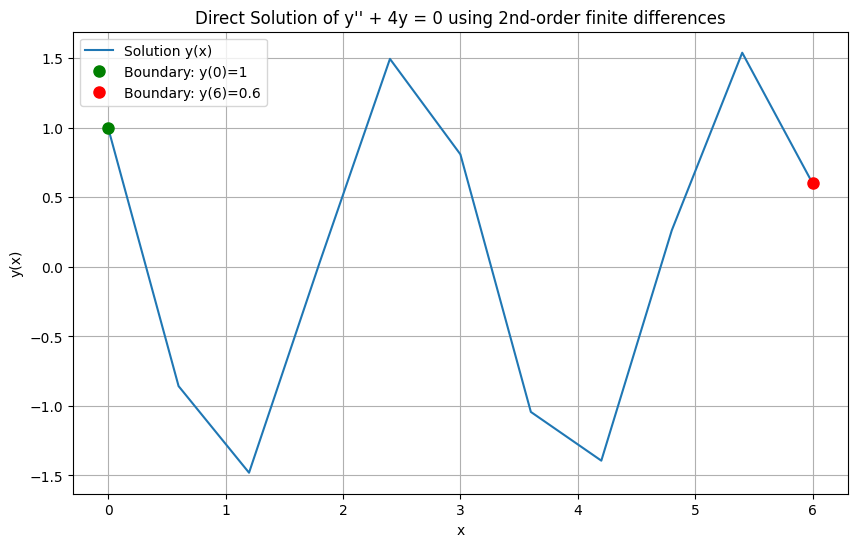

In [ ]:
import numpy as np
import matplotlib.pyplot as plt # Import matplotlib.pyplot

def setup_bvp_ypp_plus_4y(a, b, alpha, beta, N):
    h = (b - a) / N
    n = N + 1  # include boundaries

    # Tridiagonal matrix A
    main = (-2 + 4*h**2) * np.ones(n)
    off  = np.ones(n-1)

    # use diag to efficiently fill the bulk of th matrix
    A = np.diag(main) + np.diag(off, 1) + np.diag(off, -1)

    # RHS vector b
    b_vec = np.zeros(n)

    # Left boundary: y_0 = alpha
    A[0, 0] = 1.0
    A[0, 1] = 0.
    b_vec[0] = alpha

    # Right boundary: y_N = beta
    A[N, N] = 1.0
    A[N, N-1] = 0.
    b_vec[N] = beta

    return A,b_vec

def solve_bvp(a,b,A,b_vec):
    n = len(b_vec)
    y = np.linalg.solve(A, b_vec)
    x = np.linspace(a, b, n)
    return x, y

# setup linear system
a,b = 0,6
alpha,beta = 1,0.6
N = 10
A,b_vec = setup_bvp_ypp_plus_4y(a, b, alpha, beta, N)

print("A = ",A)
print("b - ",b_vec)

x,y = solve_bvp(a,b,A,b_vec)

print("x = ",x)
print("y = ",y)

# Plot the converged solution
fig1 = plt.figure(figsize=(10, 6))
plt.plot(x, y, label='Solution y(x)') # Use x, y from solve_bvp
plt.plot(a, alpha, 'go', markersize=8, label=f'Boundary: y({a})={alpha}')
plt.plot(b, beta, 'ro', markersize=8, label=f'Boundary: y({b})={beta}')
plt.title("Direct Solution of y'' + 4y = 0 using 2nd-order finite differences")
plt.xlabel('x')
plt.ylabel('y(x)')
plt.legend()
plt.grid(True)
plt.show()

Consider what happends as we change the number of nodes between $a$, and $b$.

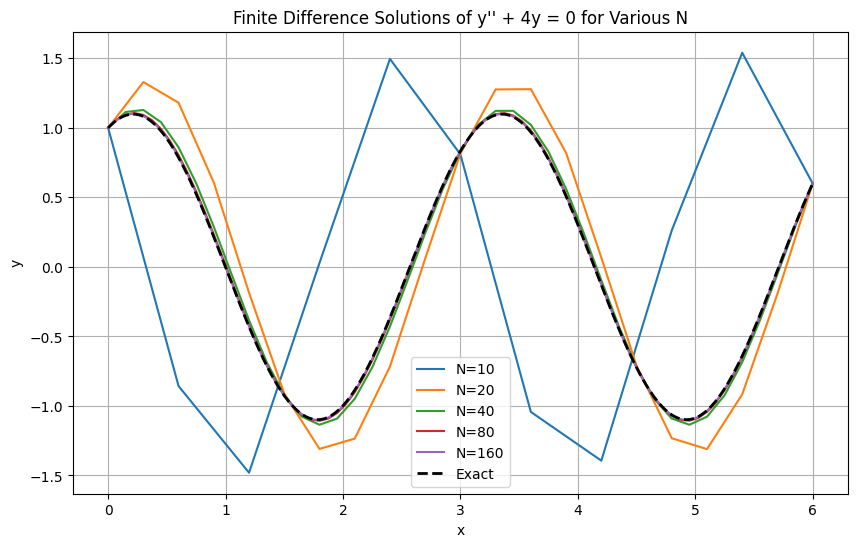

In [ ]:
import matplotlib.pyplot as plt

# Exact solution for comparison
def exact_solution(x):
    # Solve y'' + 4y = 0 with y(0)=alpha, y(1)=beta
    # General solution: y = C1 cos(2x) + C2 sin(2x)
    C1 = alpha
    C2 = (beta - alpha*np.cos(2*b)) / np.sin(2*b)
    return C1*np.cos(2*x) + C2*np.sin(2*x)

# Values of N to test
N_values = [10, 20, 40, 80, 160]

plt.figure(figsize=(10,6))

# Plot numerical solutions
for N in N_values:
    A,b_vec = setup_bvp_ypp_plus_4y(a, b, alpha, beta, N)
    x, y = solve_bvp(a, b, A, b_vec)
    plt.plot(x, y, label=f"N={N}")

# Plot exact solution
x_exact = np.linspace(a, b, 400)
plt.plot(x_exact, exact_solution(x_exact), 'k--', linewidth=2, label="Exact")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Finite Difference Solutions of y'' + 4y = 0 for Various N")
plt.legend()
plt.grid(True)
plt.show()

From this we can see that the error in the solution becomes negligible after 80 points.

## 📂 10.1.4 Finite Difference vs Shooting Method Solution to Boundary Value Problems

---

Finite‑difference and shooting methods both solve BVPs, but they differ in stability, robustness, and how they treat boundary conditions.

Shooting is conceptually simple but can be unstable, and is generally more computationally expensive. As we saw in our previous example in [Notebook 9.4](https://colab.research.google.com/drive/1dLZwxzQA27SfnVt4iD7lNGxu_UERgC8m?usp=playground), we had to solve initial values problems for $y_1$ and $y_2$, as well as the sensitivity parameters.

The finite‑difference approach is more robust and general, can make use of efficient (often sparse) linear solvers, stable for stiff ODEs, directly enforces exactboundary conditions, and can be extended to multi-dimensional problems and partial differential equations.

The downside to the finite-difference approach is that it requires the assembly of linear system and associated matrix.

### Pros and Cons: Shooting Method vs Finite-Difference (Direct Solution)

| Aspect | Shooting Method | Finite Difference (Direct Solution) |
|-------|------------------|--------------------------------------|
| Conceptual Simplicity | Converts BVP → IVP; intuitive root-finding on initial slope. | Requires discretisation and assembling a linear/nonlinear system. |
| Implementation Effort | Low: reuse IVP solvers + scalar root-finding. | Higher: build matrix (often tridiagonal) and solve globally. |
| Stability | Can be unstable for stiff/sensitive problems; endpoint blow-up common. | Generally stable; central differences robust for stiff/nonlinear BVPs. |
| Accuracy | High for simple linear problems; sensitive to stiffness. | Very good; improves systematically with mesh refinement. |
| Convergence Behaviour | Root-finding may fail or converge to wrong branch. | Newton iterations on global system converge reliably. |
| Boundary Conditions | Best for Dirichlet–Dirichlet; mixed BCs awkward. | Handles Dirichlet, Neumann, Robin uniformly. |
| Multiple Solutions | May converge to unintended branch. | Can track multiple branches via nonlinear solves. |
| Computational Cost | Fast for simple linear cases. | O(N) for linear tridiagonal solves; iterative for nonlinear. |
| Generalisability | Limited to 1D ODEs. | Extends naturally to PDEs and multidimensional grids. |
| Mesh Control | Adaptive IVP solvers give automatic step control. | Explicit grid design required; uneven spacing possible. |
| Failure Modes | IVP instability or poor initial guess → divergence. | Poor discretisation → global error; Jacobian assembly needed. |

Don't worry about the specific terms for types of **boundary conditions** at this stage. Will will circle back to this.

## 📂 10.1.5 Relaxation Method for Finite Difference Solutions

---

While the Direct Solution methods can often take advantage of the sparse nature of the linear system associated with the finite difference approximation of the ODE, a large problem can still requires the storage of at least the non-zero tridiagonal values. This is even worse and requires more memory for dense matrices associated with higher order derivatives or more accurate finite difference stencils - which from section 10.1.1, require more adjacent terms in the stencil and less non-zero values in the system matrix.

You may recall that in Week 2, we briefly discussed iterative methods for solving matrices. Well, we can use the same sort of approaches here to solve the finite-difference generated linear system,
$$\mathbf{A}\cdot\mathbf{y}=\mathbf{b},$$
for $\mathbf{y}$, or avoid having to construct the matrix $\mathbf{A}$, altogether.

Again this process is best described by considering its application to our example ODE,

$$y''+4y = 0.$$

As we did in Section 10.1.3, we can represent the $y''$ in terms of a second order accurate central difference, such that the ODE about a point $x_i$, can be approximated as

$$\frac{y(x_{i+1})-2y(x_i)+y(x_{i-1})}{h^2}+4y(x_i)+\mathcal{O}(h^2) = 0.$$

We can define a residual, $R_i$ at each point in the domain,
$$R_i = \frac{y(x_{i+1})-2y(x_i)+y(x_{i-1})}{h^2}+4y(x_i),$$

which should be zero when values of $y$ at all points in the domain are correct.

Instead of arranging this expression as a linear equation in terms of adjacent values of $y$, we can instead arrange this as an expression for $y(x_i)$ as

\begin{align}
\left(4h^2-2\right)y(x_i)&=-y(x_{i+1})-y(x_{i-1})\\
y(x_i) &= \frac{y(x_{i+1})+y(x_{i-1})}{2-4h^2}.
\end{align}

As presented here, this only allows us to calculate $y(x_i)$ if we already know $y$ at the surrounding points, which we do not.

This is where we introduce the **relaxation**. Instead of strictly enforcing this, we will *relax* the solution, as calculate a new value of $y$ that satisfies the ODE based on the current surrounding values, i.e.

$$y^{k+1}(x_i) = \frac{y^k(x_{i+1})+y^k(x_{i-1})}{2-4h^2},\tag{10.4}$$

where $k$ is the current iteration. This process is repeated over all points in the discretised solution domain, updating $y$ at each point until
$$\max_i|R_i| < ϵ,$$

where $|R_i|$ is the magnitude of the residual at a point, $i$, and $\epsilon$ is a chosen tolerance for the solution.

The specific *relaxation* formulation used in Equation 10.4, is referred to as **Jacobi relaxation**. This is a simple, but less rapidly convergent form.

A faster and more stable form is that of **Gauss-Seidel Relaxation**, where you use the most recent version of the adjacent point, i.e. if in your sweep you update $i-1$ before point $i$, then use this rather than the value from the previous iteration, i.e.

$$y^{k+1}(x_i) = \frac{y^k(x_{i+1})+y^{k+1}(x_{i-1})}{2-4h^2},\tag{10.5}$$

You will encounter many other options out in the wild.

This method can be solved by cycling through each point in the solution domain, without needing to formulate a large matrix.

h = 1.0000
Number of total points = 7
Starting Jacobi Relaxation...
Iteration 0, Max Residual: 3.47e+00
Converged after 123 iterations. Max residual: 7.65e-08


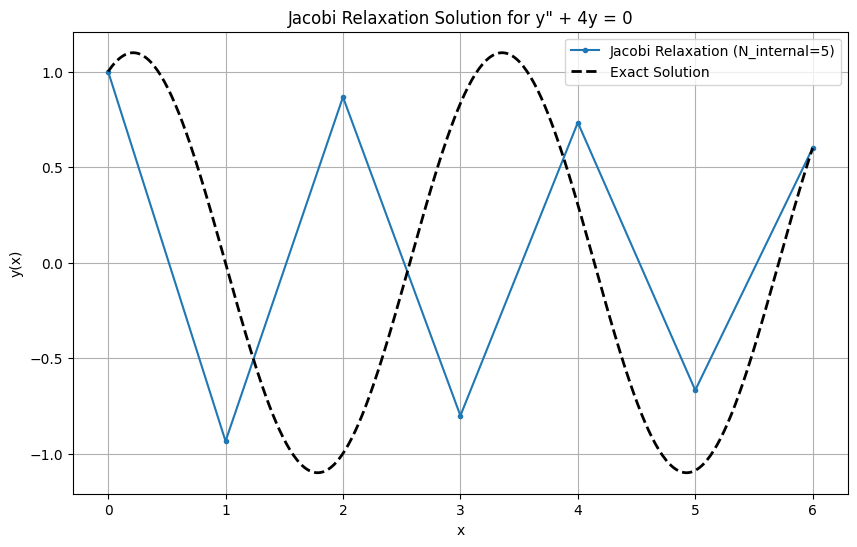

In [ ]:
# @title 💻 Jacobi Relaxation
Npoints = 5 # @param {"type":"number","placeholder":"5"}
import numpy as np
import matplotlib.pyplot as plt

# Parameters for the BVP
a = 0.0
b = 6.0
alpha = 1.0  # y(0) = 1
beta = 0.6   # y(6) = 0.6

# Number of internal points (N_internal)
# Total points including boundaries will be N_internal + 2
# For Jacobi to converge with y'' + 4y = 0, h must be >= 1.
# h = (b-a) / (N_internal + 1). So (6-0) / (N_internal + 1) >= 1 => 6 >= N_internal + 1 => N_internal <= 5.
# Choosing N_internal = 3 to ensure h > 1 for clear convergence demonstration.
N_internal = Npoints # Reduced to ensure Jacobi convergence (h=1.5)
n_total = N_internal + 2 # Total points including boundaries

# Discretization
h = (b - a) / (n_total - 1)
x = np.linspace(a, b, n_total)

# Initial guess for y (linear interpolation between boundary conditions)
y = np.linspace(alpha, beta, n_total)

# Jacobi Relaxation parameters
max_iterations = 20000 # Increased max_iterations for potentially slow convergence
tolerance = 1e-7     # Adjusted tolerance for convergence

print(f"h = {h:.4f}")
print(f"Number of total points = {n_total}")

# Jacobi Relaxation loop
print("Starting Jacobi Relaxation...")
for iteration in range(max_iterations):
    y_old = np.copy(y) # Store previous iteration's values

    # Update internal points using the Jacobi formula
    # y_i = (y_{i+1} + y_{i-1}) / (2 - 4*h**2)
    denominator = (2 - 4 * h**2)
    if abs(denominator) < 1e-10: # Check for near-zero denominator
        print("Warning: Denominator in Jacobi formula is near zero. Adjust h or N_internal.")
        break

    for i in range(1, n_total - 1): # Iterate over internal points (excluding boundaries)
        y[i] = (y_old[i+1] + y_old[i-1]) / denominator

    # Calculate residual (using current y values for ODE check)
    # Note: Residuals are calculated using the updated 'y' for current iteration evaluation.
    residuals = np.zeros(N_internal)
    for i in range(1, n_total - 1):
        # R_i = (y(x_{i+1})-2y(x_i)+y(x_{i-1}))/h^2+4y(x_i)
        residuals[i-1] = (y[i+1] - 2*y[i] + y[i-1]) / h**2 + 4*y[i]

    max_residual = np.max(np.abs(residuals))

    if max_residual < tolerance:
        print(f"Converged after {iteration + 1} iterations. Max residual: {max_residual:.2e}")
        break

    if iteration % 1000 == 0: # Print progress periodically
        print(f"Iteration {iteration}, Max Residual: {max_residual:.2e}")

    if iteration == max_iterations - 1:
        print(f"Did not converge after {max_iterations} iterations. Final Max residual: {max_residual:.2e}")

# Exact solution for comparison
def exact_solution(x_val):
    # General solution: y = C1 cos(2x) + C2 sin(2x)
    # Apply boundary conditions y(a)=alpha, y(b)=beta
    C1 = alpha
    # Check for sin(2*b) being zero to avoid division by zero for certain 'b' values.
    # For b=6, sin(2*b) = sin(12) is not zero.
    sin_2b = np.sin(2 * b)
    if abs(sin_2b) < 1e-10:
        print("Warning: sin(2*b) is near zero, exact solution might be ill-defined or require special handling.")
        # Fallback to a simple solution if sin(2*b) is zero and cos(2*b) is 1 or -1
        # This simplified handling might not be correct for all such cases.
        if abs(np.cos(2*b) - 1) < 1e-10: # If 2*b is a multiple of 2*pi
            C2 = (beta - alpha) / (2*b) # Example: y = C1 + C2*x for y''=0
        elif abs(np.cos(2*b) + 1) < 1e-10: # If 2*b is an odd multiple of pi
             C2 = (beta + alpha) / (2*b)
        else:
             C2 = 0 # Default fallback, may not be accurate
    else:
        C2 = (beta - alpha * np.cos(2 * b)) / sin_2b
    return C1 * np.cos(2 * x_val) + C2 * np.sin(2 * x_val)

# Plot the solution
plt.figure(figsize=(10, 6))
plt.plot(x, y, label=f'Jacobi Relaxation (N_internal={N_internal})', marker='o', markersize=3, linestyle='-')

x_exact = np.linspace(a, b, 400)
plt.plot(x_exact, exact_solution(x_exact), 'k--', linewidth=2, label="Exact Solution")

plt.title('Jacobi Relaxation Solution for y" + 4y = 0')
plt.xlabel('x')
plt.ylabel('y(x)')
plt.grid(True)
plt.legend()
plt.show()

You will notice that in this particular case the Jacobi Method blows up (diverges)when there are more than 5 points.

### Gauss-Seidel Relaxation

Gauss-Seidel relaxation is an improvement over the Jacobi method because it uses the most recently updated values of `y` as soon as they are available within the same iteration. This often leads to faster convergence.

If you limits both the Jacobi above, and Gauss-Seidel below, to 5 internal points (7 points total), you will see that the Gauss-Seidel method takes half the iterations of the Jacobi.

h (Gauss-Seidel) = 1.0000
Number of total points (Gauss-Seidel) = 7
Starting Gauss-Seidel Relaxation...
Gauss-Seidel Iteration 0, Max Residual: 1.20e+00
Gauss-Seidel Converged after 53 iterations. Max residual: 8.97e-08


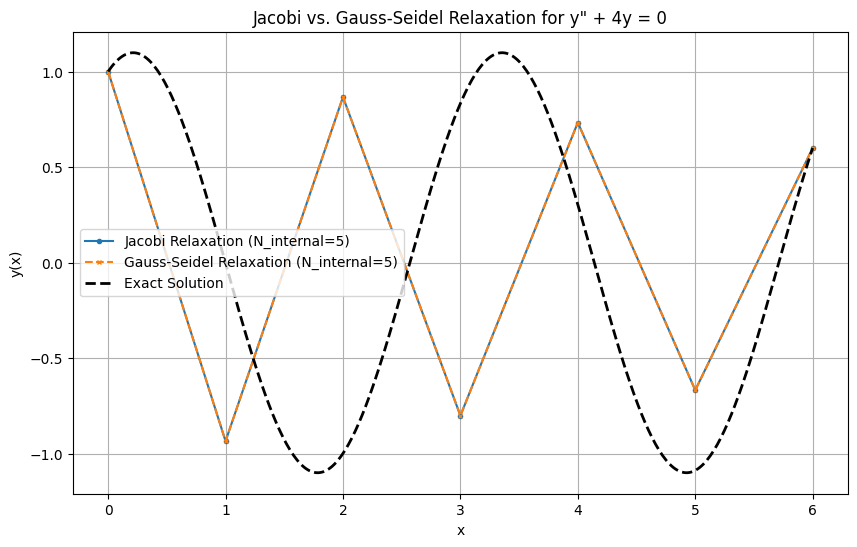

In [ ]:
# @title ####💻 Gauss-Seidel Relaxation Code
Npoints = 5 # @param {"type":"number","placeholder":"5"}
import numpy as np
import matplotlib.pyplot as plt

# Parameters (same as for Jacobi)
a = 0.0
b = 6.0
alpha = 1.0  # y(0) = 1
beta = 0.6   # y(6) = 0.6

# Using the same N_internal as the converged Jacobi case for direct comparison.
# For Jacobi to converge with y'' + 4y = 0, h must be >= 1.
# h = (b-a) / (N_internal + 1). So (6-0) / (N_internal + 1) >= 1 => 6 >= N_internal + 1 => N_internal <= 5.
N_internal_gs = Npoints # Using the same N_internal as the previous Jacobi demonstration
n_total_gs = N_internal_gs + 2 # Total points including boundaries

# Discretization
h_gs = (b - a) / (n_total_gs - 1)
x_gs = np.linspace(a, b, n_total_gs)

# Initial guess for y (linear interpolation between boundary conditions)
y_gs = np.linspace(alpha, beta, n_total_gs)

# Gauss-Seidel Relaxation parameters
max_iterations_gs = 20000
tolerance_gs = 1e-7

print(f"h (Gauss-Seidel) = {h_gs:.4f}")
print(f"Number of total points (Gauss-Seidel) = {n_total_gs}")

# Gauss-Seidel Relaxation loop
print("Starting Gauss-Seidel Relaxation...")
for iteration_gs in range(max_iterations_gs):
    y_old_gs = np.copy(y_gs) # Store previous iteration's values for convergence check

    # Update internal points using the Gauss-Seidel formula
    # y_i = (y_{i+1} + y_{i-1}) / (2 - 4*h**2)
    denominator_gs = (2 - 4 * h_gs**2)
    if abs(denominator_gs) < 1e-10:
        print("Warning: Denominator in Gauss-Seidel formula is near zero. Adjust h or N_internal.")
        break

    for i in range(1, n_total_gs - 1): # Iterate over internal points
        # Key difference: use y_gs[i-1] which might have already been updated in this iteration
        y_gs[i] = (y_gs[i+1] + y_gs[i-1]) / denominator_gs

    # Calculate residual for convergence check
    residuals_gs = np.zeros(N_internal_gs)
    for i in range(1, n_total_gs - 1):
        residuals_gs[i-1] = (y_gs[i+1] - 2*y_gs[i] + y_gs[i-1]) / h_gs**2 + 4*y_gs[i]

    max_residual_gs = np.max(np.abs(residuals_gs))

    if max_residual_gs < tolerance_gs:
        print(f"Gauss-Seidel Converged after {iteration_gs + 1} iterations. Max residual: {max_residual_gs:.2e}")
        break

    if iteration_gs % 1000 == 0:
        print(f"Gauss-Seidel Iteration {iteration_gs}, Max Residual: {max_residual_gs:.2e}")

    if iteration_gs == max_iterations_gs - 1:
        print(f"Gauss-Seidel did not converge after {max_iterations_gs} iterations. Final Max residual: {max_residual_gs:.2e}")

# Exact solution function (redefined for clarity, or ensure it's in scope)
def exact_solution_gs(x_val):
    C1_gs = alpha
    sin_2b_gs = np.sin(2 * b)
    if abs(sin_2b_gs) < 1e-10:
        C2_gs = 0 # Fallback, assumes this condition is handled by problem design
    else:
        C2_gs = (beta - alpha * np.cos(2 * b)) / sin_2b_gs
    return C1_gs * np.cos(2 * x_val) + C2_gs * np.sin(2 * x_val)

# Plot the solutions for comparison
plt.figure(figsize=(10, 6))
plt.plot(x, y, label=f'Jacobi Relaxation (N_internal={N_internal})', marker='o', markersize=3, linestyle='-') # Assuming x, y, N_internal are from previous cell
plt.plot(x_gs, y_gs, label=f'Gauss-Seidel Relaxation (N_internal={N_internal_gs})', marker='x', markersize=3, linestyle='--')

x_exact_plot = np.linspace(a, b, 400)
plt.plot(x_exact_plot, exact_solution_gs(x_exact_plot), 'k--', linewidth=2, label="Exact Solution")

plt.title('Jacobi vs. Gauss-Seidel Relaxation for y" + 4y = 0')
plt.xlabel('x')
plt.ylabel('y(x)')
plt.grid(True)
plt.legend()
plt.show()

---
Why do both these relaxation methods fail when the number of points increases?

---
In this particular case, the iterative solution diverges. This is a function of this particular ODE, and is the result of $h^2$ becoming small, which impacts the weighting of the terms in the residual, e.g.

$$R_i = \frac{1}{h^2}y(x_{i+1})+\left(4-\frac{2}{h^2}\right)y(x_i)+\frac{1}{h^2}y(x_{i-1}).$$

As $h\rightarrow 0$, the weighting of point $i$ becomes negative, as the weighting of the diagonal points becomes strongly positive. The update for $i$ becomes dominated by its neighbours - lossing diagonal dominance.

> ### ⚠️ Point of note
> Relaxation methods can diverge if the finite difference approximation to the ODE is not diagonally dominant.

Consider instead the problem
$$ y'' = 10$$

where the finite difference leads to
$$\frac{y(x_{i+1})-2y(x_i)+y(x_{i-1})}{h^2}+\mathcal{O}(h^2) = 10,$$

which we leads to following expression for $y(x_i)$ as

$$y(x_i) = \frac{y(x_{i+1})+y(x_{i-1})-10h^2}{2}.$$

The Jacobi relaxation in this case becomes

$$y^{k+1}(x_i) = \frac{y^k(x_{i+1})+y^k(x_{i-1})-10h^2}{2},$$

which no longer has the problem of the relative weighting of the different nodes changing as $h\rightarrow 0$.

The Jacobi Relaxation Solution of this problem is calculated below based on condition $y(0) = 1$ and $y(6)=0.6$.

h = 0.1176
Number of total points = 52
Starting Jacobi Relaxation for y'' = 10...
Iteration 0, Max Residual: 1.00e+01
Iteration 1000, Max Residual: 1.90e+00
Iteration 2000, Max Residual: 2.85e-01
Iteration 3000, Max Residual: 4.27e-02
Iteration 4000, Max Residual: 6.39e-03
Iteration 5000, Max Residual: 9.58e-04
Iteration 6000, Max Residual: 1.43e-04
Iteration 7000, Max Residual: 2.15e-05
Iteration 8000, Max Residual: 3.22e-06
Iteration 9000, Max Residual: 4.82e-07
Converged after 9830 iterations. Max residual: 9.99e-08


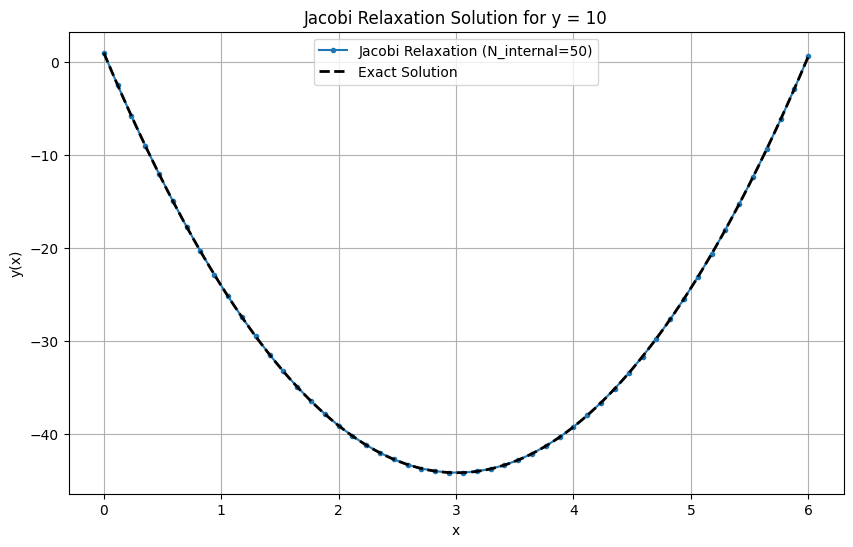

In [ ]:
# @title 💻 Jacobi Relaxation for y'' = 10
Npoints = 50 # @param {"type":"number","placeholder":"5"}
import numpy as np
import matplotlib.pyplot as plt

# Parameters for the BVP y'' = 10
a = 0.0
b = 6.0
alpha = 1.0  # y(0) = 1
beta = 0.6   # y(6) = 0.6

# Number of internal points (N_internal)
N_internal = Npoints
n_total = N_internal + 2 # Total points including boundaries

# Discretization
h = (b - a) / (n_total - 1)
x = np.linspace(a, b, n_total)

# Initial guess for y (linear interpolation between boundary conditions)
y = np.linspace(alpha, beta, n_total)

# Jacobi Relaxation parameters
max_iterations = 20000
tolerance = 1e-7

print(f"h = {h:.4f}")
print(f"Number of total points = {n_total}")

# Jacobi Relaxation loop
print("Starting Jacobi Relaxation for y'' = 10...")
for iteration in range(max_iterations):
    y_old = np.copy(y) # Store previous iteration's values

    # Update internal points using the Jacobi formula for y'' = 10
    # (y_{i+1} - 2y_i + y_{i-1}) / h**2 = 10
    # y_i = (y_{i+1} + y_{i-1} - 10 * h**2) / 2
    denominator = 2.0

    for i in range(1, n_total - 1): # Iterate over internal points (excluding boundaries)
        y[i] = (y_old[i+1] + y_old[i-1] - 10 * h**2) / denominator

    # Calculate residual for y'' = 10
    residuals = np.zeros(N_internal)
    for i in range(1, n_total - 1):
        residuals[i-1] = (y[i+1] - 2*y[i] + y[i-1]) / h**2 - 10

    max_residual = np.max(np.abs(residuals))

    if max_residual < tolerance:
        print(f"Converged after {iteration + 1} iterations. Max residual: {max_residual:.2e}")
        break

    if iteration % 1000 == 0: # Print progress periodically
        print(f"Iteration {iteration}, Max Residual: {max_residual:.2e}")

    if iteration == max_iterations - 1:
        print(f"Did not converge after {max_iterations} iterations. Final Max residual: {max_residual:.2e}")

# Exact solution for y'' = 10
def exact_solution_y10(x_val):
    # General solution: y = 5x^2 + C1x + C2
    # Apply boundary conditions y(0)=alpha, y(b)=beta
    C2 = alpha
    C1 = (beta - alpha - 5 * b**2) / b
    return 5 * x_val**2 + C1 * x_val + C2

# Plot the solution
plt.figure(figsize=(10, 6))
plt.plot(x, y, label=f'Jacobi Relaxation (N_internal={N_internal})', marker='o', markersize=3, linestyle='-')

x_exact = np.linspace(a, b, 400)
plt.plot(x_exact, exact_solution_y10(x_exact), 'k--', linewidth=2, label="Exact Solution")

plt.title('Jacobi Relaxation Solution for y'' = 10')
plt.xlabel('x')
plt.ylabel('y(x)')
plt.grid(True)
plt.legend()
plt.show()

## 📂 10.1.6 Direct Solve vs Relaxation Methods for Finite-Difference Boundary Value Problems

---

| Aspect | Direct Finite-Difference Solve | Relaxation (Jacobi / GS) |
|--------|--------------------------------|-----------------------------------|
| Core Idea | Assemble linear system and solve globally (often tridiagonal). | Iteratively update grid values until residuals vanish. |
| Convergence | Guaranteed for linear BVPs; one solve gives exact FD solution. | Depends on the ODE; may diverge for stiff/Helmholtz-type operators. |
| Stability | Very stable; unaffected by step size. | Can be unstable for small \(h\). |
| Speed | \(O(N)\) for tridiagonal systems; very fast. | Potentially slow; many iterations required. |
| Implementation | Requires matrix assembly and a linear solver. | Very simple update rules; easy to code. |
| Memory Use | Minimal (tridiagonal). | Minimal; only grid values stored. |
| Nonlinear Problems | Requires Newton/Krylov methods; more complex. | Naturally handles nonlinear residuals via Newton-relaxation. |
| Boundary Conditions | Straightforward for Dirichlet/Neumann/Robin. | Also straightforward; BCs fixed each iteration. |
| Sensitivity to Step Size | Stable for any \(h\). | Small \(h\) can cause divergence (Jacobi especially). |
| Parallelisation | Harder (global solve). | Easy (Jacobi is fully parallelisable). |
| When It Excels | Linear, well-conditioned BVPs; large grids. | Nonlinear BVPs, PDEs, or when direct solvers are unavailable. |


## 🔗 Bridge to Notebook 10.2

This notebook introduced finite difference methods as an alternative approach to solving boundary value problems (BVPs), contrasting them with the shooting method. You should be able to approximate derivatives using various stencils (forward, backward, central difference) and then applied these approximations to discretise an ordinary differential equation (ODE) into a system of linear equations across a grid of points.

The notebook then explored two main strategies for solving these linear systems: direct solution and relaxation methods. You should be able to formulate solutions to similar ODEs using both methods, and appreciate in which context a direct or relaxation methods may be more appropriate.

In Notebook 10.2, we will look at how ODEs and Machine Learning Methods can be combined into Neural ODEs.

#🤖 AI Acknowledgment

MS CoPilot v25.6.440430001 was used to proof read this notebook and provided the code for the Direct and Relaxation based solvers. These were modified to include the code input forms to help enable efficient experimentation in terms of the chosen number of discretised points.